<h1>Import libraries

In [1]:
from pathlib import Path

# Locate shared data from the repository root or any notebook subfolder.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "1 Data Cleaning").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
DATA_DIR = PROJECT_ROOT / "data"

import random
import pandas as pd
import numpy as np
import io
import base64

<h1>Load data and slicing

In [4]:
patrol_timings = pd.read_csv((DATA_DIR / 'patrol timings.csv'),index_col=1)
patrol_timings = patrol_timings.iloc[:,1:]

patrol_timings

,Amount of time to patrol
Places,
Bishan East,84
Marymount,61
Upper Thomson,76
Alexandra Hill,89
Alexandra North,69
...,...
Seletar Hills,87
Serangoon Central,66
Serangoon Garden,102


In [5]:
# Load data
df_time_updated = pd.read_csv((DATA_DIR / 'df_time.csv'), index_col=0)
hq_to_locations = pd.read_csv((DATA_DIR / 'hq to locations.csv'), index_col=0)

#slicing
hq_to_locations = hq_to_locations.iloc[:, ::8]
df_time_updated = df_time_updated.iloc[::8,::8]
patrol_timings = patrol_timings.iloc[::8, :]

In [6]:
print(patrol_timings.shape)
print(df_time_updated.shape)
print(hq_to_locations.shape)

(38, 1)
(38, 38)
(7, 38)


In [7]:
#hq_to_locations
#df_time_updated
patrol_timings

,Amount of time to patrol
Places,
Bishan East,84
Everton Park,84
Telok Blangah Way,63
Leedon Park,72
Marina Centre,90
Kallang Way,77
Kampong Bugis,81
Marine Parade,67
Newton Circus,75


<h1>Data cleaning

In [8]:
# Strip whitespace from all names
df_time_updated.index = df_time_updated.index.str.strip()
df_time_updated.columns = df_time_updated.columns.str.strip()
hq_to_locations.index = hq_to_locations.index.str.strip()
hq_to_locations.columns = hq_to_locations.columns.str.strip()

# Clean up patrol and HQ names
locations = list(df_time_updated.index)
hq_names = list(hq_to_locations.index)

locations = [loc.strip() for loc in locations]
hq_names = [hq.strip() for hq in hq_names]
locations = list(dict.fromkeys(locations))
hq_names = list(dict.fromkeys(hq_names))

print(len(locations))
print(len(hq_names))

# Combined list of all nodes
V = list(dict.fromkeys(locations + hq_names))
N = locations
H = hq_names

# Complete travel time matrix 
T = df_time_updated.copy()
for hq in H:
    T.loc[hq] = hq_to_locations.loc[hq]
    T[hq] = hq_to_locations.loc[hq]
T = T.fillna(99999)
#T

38
7


In [9]:
np.sum(patrol_timings)

c:\Users\carri\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


Amount of time to patrol    2836
dtype: int64

In [10]:
# Find the minimum value in each row of T and sum them up
row_mins = T.min(axis=1)
total_min_sum = row_mins.sum()
print("Sum of row minimums:", total_min_sum)

# this is a lower bound (but too loose)
# i think gurobi's lower bound was 1600+. but this was the first LP relaxation, the lower bound can be better

Sum of row minimums: 357.0


<h1>Functions

In [11]:
def patrol_time(location):
    # Add bounds checking
    if location >= len(patrol_timings) or location < 0:
        print(f"Error: patrol_time location {location} out of bounds (max: {len(patrol_timings)-1})")
        return 0
    return patrol_timings.iloc[location, 0]

def travel_time(location1, location2):
    # Add bounds checking
    if location1 >= len(T) or location2 >= len(T.columns) or location1 < 0 or location2 < 0:
        print(f"Error: travel_time locations {location1}, {location2} out of bounds (max: {len(T)-1}, {len(T.columns)-1})")
        return 0
    return T.iloc[location1, location2]

def arrival_time(ls):
    if ls is None or len(ls) < 2 or (len(ls) == 2 and ls[0]==ls[1]):
        return 0
    # sum patrol time location
    total_time = sum(patrol_time(location) for location in ls[1:-1])
    # add travel time for every consevutive pair
    for i in range(len(ls)-1):
        total_time += travel_time(ls[i],ls[i+1])
    return total_time

def latest_arrival_time(encoding):
    return max(arrival_time(ls) for ls in encoding.values() if ls is not None)

def objective_value(encoding):
    objective = 0
    for ls in encoding.values():
        if len(ls) > 2:   
            for i in range(len(ls)-1):  
                    objective += travel_time(ls[i],ls[i+1])
    return objective
        
def feasible(ls): # returns True or False
    return arrival_time(ls) <= 600

def feasible_solution(encoding):
    for ls in encoding.values():
        if not feasible(ls):
            return False
    return True

def no_of_locations(encoding):
    return [len(v)-2 for v in encoding.values() if v is not None]

def summary(encoding):
    print(
        f"Feasible: {feasible_solution(encoding)}\n"
        f"Objective Value: {objective_value(encoding)}\n"
        f"Latest Arrival Time: {latest_arrival_time(encoding)}\n"
        f"No. of Locations Each FRC visits: between {min(no_of_locations(encoding))} and {max(no_of_locations(encoding))}\n"
    )

# Print which vehicles are used, their total time, and their routes\
def route(encoding):
    if feasible_solution(encoding):
        for k in encoding:
            if encoding[k] is None:
                print(f"\nVehicle {k} is not used.")
            else:
                print(f"\nTotal time {k}: {arrival_time(encoding[k])}")
                print(f"Route for vehicle {k}: ", end =" ")
                print(*encoding[k],sep='->')
    else:
        print("❌ No feasible solution found.")

### Map (Folium)

In [12]:
coordinates = pd.read_csv((DATA_DIR / 'singapore_city_coordinates_improved.csv'))
policehqs = pd.read_csv((DATA_DIR / 'policeheadquarters.csv'))

coordinates.dropna(subset=['latitude' , 'longitude'], inplace=True)
coordinates = coordinates[(coordinates.Place != 'Park') 
                      & (coordinates.Place != 'Trafalgar') 
                      & (coordinates.Place != 'Semakau')
                      & (coordinates.Place != 'Sudong')
                      & (coordinates.Place != 'Straits View')
                      & (coordinates.Place != 'City Terminals')
                      & (coordinates.Place != 'Murai')
                      & (coordinates.Place != 'Lim Chu Kang')
                      & (coordinates.Place != 'Pulau Seletar')
                      & (coordinates.Place != 'North-Eastern Islands')
                      & (coordinates.Place != 'Pulau Seletar')]
coordinates.reset_index(inplace=True, drop=True)

# slice
coordinates = coordinates.iloc[::8, :]
coordinates.reset_index(drop=True, inplace=True)

# Capitalise latitude and longitude headers in coordinates DataFrame
coordinates.rename(columns={'latitude': 'Latitude', 'longitude': 'Longitude'}, inplace=True)


In [13]:
coordinates.shape[0]
coordinates

,Place,City,Area,Latitude,Longitude,bounding_box_1,bounding_box_2,bounding_box_3,bounding_box_4
0,Bishan East,Bishan,central,1.351912,103.848971,1.341685,1.367983,103.818451,103.860476
1,Everton Park,Bukit Merah,central,1.277129,103.839368,1.275955,1.277838,103.838134,103.840575
2,Telok Blangah Way,Bukit Merah,central,1.274615,103.822847,1.274611,1.274615,103.822847,103.822998
3,Leedon Park,Bukit Timah,central,1.317512,103.796463,1.317512,1.317865,103.796154,103.796463
4,Marina Centre,Downtown Core,central,1.279582,103.853830,1.279329,1.279836,103.853552,103.854107
5,Kallang Way,Geylang,central,1.324954,103.876755,1.304954,1.344954,103.856755,103.896755
6,Kampong Bugis,Kallang,central,1.308214,103.865911,1.308004,1.308214,103.865911,103.865961
7,Marine Parade,Marine Parade,central,1.302689,103.907395,1.268731,1.313194,103.875582,103.925943
8,Newton Circus,Newton,central,1.311989,103.839290,1.301989,1.321989,103.829290,103.849290
9,Somerset,Orchard,central,1.300384,103.838829,1.299814,1.300772,103.838364,103.840003


In [14]:
def map_out(encoding):
    import folium
    import random

    # Assign a color to each HQ
    hq_colors = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'cadetblue']
    len_locations = coordinates.shape[0]
    hq_indices = list(range(len_locations, len_locations+7))
    hq_color_map = {hq_idx: hq_colors[i % len(hq_colors)] for i, hq_idx in enumerate(hq_indices)}

    # Helper: get location name from index
    def get_location_name(idx):
        if idx < len_locations:
            return T.index[idx]
        else:
            # HQ: get from policehqs DataFrame
            return policehqs.iloc[idx - len_locations, 0]

    # Helper: get lat/lon from name and source
    def get_latlon(idx, name):
        if idx < len_locations:
            row = coordinates.loc[coordinates['Place'] == name]
        else:
            row = policehqs.loc[policehqs['Division'] == name]
        if not row.empty:
            return row.iloc[0]['Latitude'], row.iloc[0]['Longitude']
        return None, None

    # Center map on Singapore
    m = folium.Map(location=[1.3521, 103.8198], zoom_start=12)

    for frc, route in encoding.items():
        if route is not None:
            hq_idx = route[0]
            color = hq_color_map.get(hq_idx, 'black')
            latlons = []
            for idx in route:
                name = get_location_name(idx)
                lat, lon = get_latlon(idx, name)
                if lat is not None and lon is not None:
                    latlons.append((lat, lon))
            # Draw the route
            folium.PolyLine(latlons, color=color, weight=3, opacity=0.7, tooltip=frc).add_to(m)
            # Optionally, mark start/end
            if latlons:
                folium.Marker(latlons[0], icon=folium.Icon(color=color, icon='home'), tooltip=f"{frc} HQ").add_to(m)

    return m



### Solution Encoding
- row_dict is a dictionary containing numbers as the keys, the location names as the value. it's from 0 to 45. 0 to 37 are the locations, 38 to 44 are the hqs.


In [41]:
# check if slicing is correct for greedy
locations_T_check = pd.read_csv((DATA_DIR / 'df_time.csv') )
hq_T_check = pd.read_csv((DATA_DIR / 'hq to locations.csv'))
S_check = pd.read_csv((DATA_DIR / 'patrol timings.csv'), index_col=1 )

######################## slicing ########################################
    # need to do this to keep the index while slicing
    # Step 1: Slice rows every 8th (e.g., 0, 8, 16, ...)
locations_T_rows_check = locations_T_check.iloc[::8, :]

    # Step 2: Select the first column (column 0) + every 8th column starting from column 1
locations_T_first_col_check = locations_T_rows_check.iloc[:, [0]]               # first column
locations_T_sliced_cols_check = locations_T_rows_check.iloc[:, 1::8]            # every 8th column starting from index 1

    # Step 3: Concatenate them back
locations_T_check = pd.concat([locations_T_first_col_check, locations_T_sliced_cols_check], axis=1)

    # Step 4: Reset the index so it becomes 0,1,2,...
locations_T_check.reset_index(drop=True, inplace=True)

    # slice hq
hq_T_check = hq_T_check.iloc[:, ::8]

    # slice patrol timing
S_check = S_check.iloc[::8, :]

# S_check
# locations_T_check
hq_T_check

# locations_T_check.shape[0]

,index_column,Depot Road,Telok Blangah Rise,Holland Road,Clifford Pier,Geylang East,Kallang Bahru,Katong,Monk's Hill,Boulevard,...,Jurong River,Chin Bee,Gul Circle,Tuas Bay,Kebun Baru,Yio Chu Kang West,Lorong Halus,Waterway East,Lorong Halus North,Upper Paya Lebar
0,Ang Mo Kio Division HQ,24,25,19,20,18,17,21,15,22,...,32,32,32,34,10,2,17,15,15,19
1,Bedok Division HQ,26,24,21,21,14,11,14,18,21,...,34,34,37,39,21,22,19,23,17,13
2,Central Division HQ,12,7,15,11,19,16,15,15,10,...,21,23,28,27,22,23,23,27,21,21
3,Clementi Division HQ,14,18,15,22,27,25,25,27,22,...,10,14,19,18,24,28,33,34,31,29
4,Jurong Division HQ,19,23,22,28,29,27,31,27,28,...,11,7,11,13,26,27,35,32,33,30
5,Tanglin Division HQ,16,17,11,12,15,13,17,7,14,...,25,26,28,31,14,15,21,21,19,17
6,Woodlands Division HQ,27,31,27,29,28,26,30,24,31,...,28,24,24,26,17,16,22,21,20,26


In [102]:
# check how it looks like without slice
locations_T_check = pd.read_csv((DATA_DIR / 'df_time.csv') )
hq_T_check = pd.read_csv((DATA_DIR / 'hq to locations.csv'))
S_check = pd.read_csv((DATA_DIR / 'patrol timings.csv'), index_col=1 )

# S_check
# locations_T_check
hq_T_check

,index_column,Bishan East,Marymount,Upper Thomson,Alexandra Hill,Alexandra North,Bukit Ho Swee,Bukit Merah,Depot Road,Everton Park,...,Fernvale,Lorong Halus North,Rivervale,Sengkang West,Lorong Chuan,Seletar Hills,Serangoon Central,Serangoon Garden,Serangoon North,Upper Paya Lebar
0,Ang Mo Kio Division HQ,9,12,15,24,24,26,24,24,24,...,13,15,15,16,10,9,14,12,8,19
1,Bedok Division HQ,19,19,21,25,25,26,22,26,23,...,25,17,21,20,19,22,20,21,20,13
2,Central Division HQ,20,20,22,11,11,9,8,12,2,...,27,21,21,24,20,24,21,23,21,21
3,Clementi Division HQ,22,20,19,13,13,18,17,14,17,...,32,31,31,35,22,28,25,27,26,29
4,Jurong Division HQ,24,21,20,19,19,24,22,19,24,...,32,33,32,32,23,28,27,29,28,30
5,Tanglin Division HQ,11,12,13,16,16,13,16,16,15,...,19,19,18,21,11,15,14,14,13,17
6,Woodlands Division HQ,20,21,19,27,27,32,29,27,31,...,20,20,24,21,19,16,23,22,18,26


### greedy

In [15]:
def greedy_initial():

    locations_T = pd.read_csv((DATA_DIR / 'df_time.csv') )
    hq_T = pd.read_csv((DATA_DIR / 'hq to locations.csv'))
    S = pd.read_csv((DATA_DIR / 'patrol timings.csv'), index_col=1 )


######################## slicing ########################################
    # need to do this to keep the index while slicing
    # Step 1: Slice rows every 8th (e.g., 0, 8, 16, ...)
    locations_T_rows = locations_T.iloc[::8, :]

    # Step 2: Select the first column (column 0) + every 8th column starting from column 1
    locations_T_first_col = locations_T_rows.iloc[:, [0]]               # first column
    locations_T_sliced_cols = locations_T_rows.iloc[:, 1::8]            # every 8th column starting from index 1

    # Step 3: Concatenate them back
    locations_T = pd.concat([locations_T_first_col, locations_T_sliced_cols], axis=1)

    # Step 4: Reset the index so it becomes 0,1,2,...
    locations_T.reset_index(drop=True, inplace=True)

    # slice hq
    hq_T = hq_T.iloc[:, ::8]

    # slice patrol timing
    S = S.iloc[::8, :]
############################################################################

    T = pd.concat([locations_T, hq_T], ignore_index=True)
    random.seed(1)
    num_locations = locations_T.shape[0]
    num_hqs = 7
    num_frcs = 7
    frcs_per_hq = num_frcs // num_hqs  # 8 FRCs per HQ
    avg_locations_per_frc = num_locations // num_frcs  # This will be 5 for now
    row_dict = {i: name for i, name in enumerate(T.iloc[:, 0])} # i: name  for each pair in enumerate. enumerate is for all
    hq_names = [row_dict[i] for i in range(num_locations, num_locations+7)]
    frc_names = [f"hq{i+1}_frc{j+1}" for i in range(num_hqs) for j in range(frcs_per_hq)]
    T = np.copy(locations_T.iloc[:,1:].to_numpy())
    HQ = np.copy(hq_T.iloc[:,1:].to_numpy())
    S = S['Amount of time to patrol'].to_numpy()

    encoding = dict.fromkeys(frc_names)
    sum_time = dict.fromkeys(frc_names , 0)
    routes = dict.fromkeys(frc_names , np.array([], dtype=int))
    unavailable_locations = []

    while np.min(T) != 99999:

        for idx, car in enumerate(encoding):
            # print('\ncar: ', car)

            if routes[car].size == 0: # start of route
                #print('start')
                hq_node = int(car[2])-1 # retrieving the HQ number
                p2 = np.where(HQ[hq_node,:] == np.min(HQ[hq_node,:]))[0][0]  # Get nearest location from HQ
                sum_time[car] += HQ[hq_node , p2] + S[p2] # add travelling time from HQ to next and patrolling time on p2

                unavailable_locations.append(p2)

                HQ[:,p2] = 99999 # remove selection from hq to location to prevent selection for other FRC

                routes[car] = np.append(routes[car], hq_node+num_locations) # add HQ node to tour
                routes[car] = np.append(routes[car], p2) # add p2 node to tour
                # print(routes[car])

            elif routes[car][0] == routes[car][-1]:
                encoding[car] = list(routes[car])
                pass

            else:
                # print('current route: ' ,routes[car])
                # print('unavailable_locations: ' , unavailable_locations)
                p1 = routes[car][-1] # retrieve the last / current location
                # p2 = np.where(T[p1,:] == np.min(T[p1,:]))[0][0] # find the nearest location from last location
                T_copy = np.copy(T)
                T_copy[:,unavailable_locations] = 99999 
                p2 = np.where(T_copy[p1,:] == np.min(T_copy[p1,:]))[0][0] # find the nearest location from last location
                p1_to_p2 = T_copy[p1 , p2]

                HQ_copy = np.copy(HQ)
                HQ_copy[:,unavailable_locations] = 99999 
                p2_to_hq = HQ_copy[routes[car][0] - num_locations, p2]
                unavailable_locations.append(p2)

                # print('p1: ',p1)
                # print('p2: ',p2)
                # p1_to_p2 = T[p1 , p2]
                # print('p1_to_p2: ', p1_to_p2)
                patrol_p2 = S[p2]
                # print('patrol_p2: ', patrol_p2)
                # p2_to_hq = HQ[routes[car][0] - num_locations,p2]
                # print('p2_to_hq: ', p2_to_hq)

                if sum_time[car] + p1_to_p2 + patrol_p2 + p2_to_hq <= 600:  
                    routes[car] = np.append(routes[car], p2) # add p2 node to tour
                    sum_time[car] += p1_to_p2 + patrol_p2
                    T[:,p1] = 99999 
                    T[p1, :] = 99999
                    HQ[:,p1] = 99999 # remove selection from hq to location to prevent selection for other FRC

                else:                    
                    sum_time[car] += HQ[routes[car][0] - num_locations,p1]
                    routes[car] = np.append(routes[car], routes[car][0]) # add p2 node to tour
                    HQ[:,p1] = 99999 # remove selection from hq to location to prevent selection for other FRC
                    T[:,p1] = 99999 
                    T[p1, :] = 99999
                    # print('car', car)
                    # print('routes[car]', routes[car])
                    # print('sum_time[car]', sum_time[car])
                    
    # Convert all numpy arrays to lists and ensure proper format
    final_encoding = {}
    for car in encoding:
        if encoding[car] is None:
            # Convert numpy array to list and ensure all indices are valid
            route_list = [int(x) for x in routes[car] if 0 <= int(x) <= 44] ######
            final_encoding[car] = route_list
        else:
            final_encoding[car] = encoding[car]
    
    return final_encoding

encoding = greedy_initial()
print(encoding)
summary(encoding)
route(encoding)
map_out(encoding)

{'hq1_frc1': [38, 33, 0, 15, 5, 35, 16, 38], 'hq2_frc1': [39, 20, 36, 37, 34, 6, 31, 39], 'hq3_frc1': [40, 1, 2, 11, 10, 3, 32, 40], 'hq4_frc1': [41, 9, 12, 8, 13, 4, 41], 'hq5_frc1': [42, 29, 30, 27, 26, 14, 42], 'hq6_frc1': [43, 7, 22, 24, 21, 23, 43], 'hq7_frc1': [44, 17, 18, 19, 28, 25, 44]}
Feasible: True
Objective Value: 675.0
Latest Arrival Time: 598.0
No. of Locations Each FRC visits: between 5 and 6


Total time hq1_frc1: 557.0
Route for vehicle hq1_frc1:  38->33->0->15->5->35->16->38

Total time hq2_frc1: 598.0
Route for vehicle hq2_frc1:  39->20->36->37->34->6->31->39

Total time hq3_frc1: 509.0
Route for vehicle hq3_frc1:  40->1->2->11->10->3->32->40

Total time hq4_frc1: 490.0
Route for vehicle hq4_frc1:  41->9->12->8->13->4->41

Total time hq5_frc1: 405.0
Route for vehicle hq5_frc1:  42->29->30->27->26->14->42

Total time hq6_frc1: 483.0
Route for vehicle hq6_frc1:  43->7->22->24->21->23->43

Total time hq7_frc1: 469.0
Route for vehicle hq7_frc1:  44->17->18->19->28->25->

### the solution encoding dictionary
- encoding is a dictionary where the key is the name of each FRC eg. hq1_frc1, and the value is a list of location indices assigned to that FRC

# SA

In [16]:
def temp_func(T, iter):
    return T/float(1+iter), "T/float(1+iter)"

def temp_probaility(T0,  delta_E):
    import math
    return math.exp(-(delta_E/T0))

In [17]:
# This version got no duplicates
def swap_operator_SA(encoding ,T):
    """
    Randomly selects two FRCs and swaps one location between them (not HQs).
    Only performs the swap if both resulting routes are feasible and the swap improves the objective.
    This version simulates the swap on copies first, only updating the original if accepted.
    """
    import random

    frc_list = [frc for frc in encoding if encoding[frc] is not None and len(encoding[frc]) > 2] 
    if len(frc_list) < 2: # this wont actl happen, but its basically to check if there are 2 frcs in the frc_list, otherwise a swap wouldnt be possible
        return

    frc1, frc2 = random.sample(frc_list, 2)
    idx1 = random.randint(1, len(encoding[frc1]) - 2)
    idx2 = random.randint(1, len(encoding[frc2]) - 2)

    # Simulate swap on copies
    new1 = encoding[frc1][:]
    new2 = encoding[frc2][:]
    new1[idx1], new2[idx2] = new2[idx2], new1[idx1]

    # Check feasibility and improvement
    if feasible(new1) and feasible(new2):
        old_obj = objective_value({frc1: encoding[frc1], frc2: encoding[frc2]}) # uses the objective_value(encoding) function
        new_obj = objective_value({frc1: new1, frc2: new2})
        if new_obj < old_obj:
            encoding[frc1] = new1
            encoding[frc2] = new2
            return True
        else:
            # If new_obj is worse than old_obj, accept new_obj with a probability        
            acceptance_rate = random.uniform(0,1)
            if temp_probaility(T, new_obj - old_obj) > acceptance_rate:
                encoding[frc1] = new1
                encoding[frc2] = new2
                return True

In [18]:
def insertion_operator_SA(encoding,T):
    """
    Randomly selects a location from one FRC and inserts it before a random location in another FRC (can be the same FRC).
    Only performs the insertion if both resulting routes are feasible AND the move improves the objective function.
    This version simulates the move on copies first, only updating the original if accepted.
    """
    import random

    frc_list = [frc for frc in encoding if len(encoding[frc]) > 3] # check for frcs that visit at least 2 locations
    if not frc_list: 
        return

    frc_from, frc_to = random.sample(frc_list, 2) if len(frc_list) > 1 else (frc_list[0], frc_list[0])

    idx_from = random.randint(1, len(encoding[frc_from]) - 2)
    loc = encoding[frc_from][idx_from]

    # Pick a random insertion point in the target FRC (not at start)
    insert_pos = random.randint(1, len(encoding[frc_to]) - 1)

    # If same FRC and insert_pos is right after idx_from, skip (no change)
    if frc_from == frc_to and (insert_pos == idx_from or insert_pos == idx_from + 1):
        return

    # Simulate move on copies
    new_from = encoding[frc_from][:]  # copy
    new_to = encoding[frc_to][:]      # copy

    # Remove from source
    del new_from[idx_from]
    # Insert into target
    new_to.insert(insert_pos, loc)

    # Check feasibility and improvement
    if feasible(new_from) and feasible(new_to):
        old_obj = objective_value({frc_from: encoding[frc_from], frc_to: encoding[frc_to]})
        new_obj = objective_value({frc_from: new_from, frc_to: new_to})
        if new_obj < old_obj:
            encoding[frc_from] = new_from
            encoding[frc_to] = new_to
            return True
        else:
            # If new_obj is worse than old_obj, accept new_obj with a probability        
            acceptance_rate = random.uniform(0,1)
            if temp_probaility(T, new_obj - old_obj) > acceptance_rate:
                encoding[frc_from] = new_from
                encoding[frc_to] = new_to
                return True

In [19]:
import random
def two_opt_operator_SA(encoding,T): # segment reverse
    frc_list = [frc for frc in encoding if encoding[frc] is not None and len(encoding[frc]) >= 4] # checks that there are at least 4 elements in the list, so that 2-opt is possible
    if not frc_list:
        return
    frc = random.choice(frc_list)
    route = encoding[frc]
    i, j = sorted(random.sample(range(1, len(route) - 1), 2)) # samples between the 2nd element and 2nd last element
    new_route = route[:i] + route[i:j+1][::-1] + route[j+1:] # reverses the route between i and j
    if feasible(new_route):
        old_obj = objective_value({frc: route})
        new_obj = objective_value({frc: new_route})
        if new_obj <= old_obj:
            encoding[frc] = new_route
            return True
        else:
            # If new_obj is worse than old_obj, accept new_obj with a probability        
            acceptance_rate = random.uniform(0,1)
            if temp_probaility(T, new_obj - old_obj) > acceptance_rate:
                encoding[frc] = new_route
                #print("2opt worse:", new_obj-old_obj, new_obj, old_obj, i, j, route, new_route)
                return True
        
        
# What: Reverse a segment within a single FRC's route.
# How: Pick one FRC, pick two indices i < j, reverse the segment between them.
# Why: Removes route "crossings" and can greatly improve a single FRC's path.

In [20]:
import random

def cross_exchange_operator_SA(encoding,T): # segment swap between 2 frcs
    """
    Cross-exchange (interroute 2-opt):
    Selects two FRCs and exchanges a segment from each route.
    Considers all 4 segment orderings (original/reversed) and applies the best feasible improvement.
    """

    frc_list = [frc for frc in encoding if encoding[frc] is not None and len(encoding[frc]) > 4]
    if len(frc_list) < 2: # essentially checks if there are enough frcs to even swap
        return

    frc1, frc2 = random.sample(frc_list, 2) # pick 2 frcs from the list
    route1, route2 = encoding[frc1], encoding[frc2]

    # Randomly choose the segment 
    start1, end1 = sorted(random.sample(range(1, len(route1)-1),2)) # samples between 2nd element and 2nd last element
    start2, end2 = sorted(random.sample(range(1, len(route2)-1),2))
    
    # Extract segments
    seg1 = route1[start1:end1+1] 
    seg2 = route2[start2:end2+1]

    # All 4 combinations: (seg1, seg2), (seg1[::-1], seg2), (seg1, seg2[::-1]), (seg1[::-1], seg2[::-1])
    candidates = []
    for s1 in [seg1, seg1[::-1]]: 
        for s2 in [seg2, seg2[::-1]]: # permutates
            new1 = route1[:start1] + s2 + route1[end1+1:]
            new2 = route2[:start2] + s1 + route2[end2+1:]
            if feasible(new1) and feasible(new2):
                old_obj = objective_value({frc1: route1, frc2: route2})
                new_obj = objective_value({frc1: new1, frc2: new2})
                if new_obj < old_obj:
                    candidates.append((new_obj, new1, new2))
                else:
                    acceptance_rate = random.uniform(0,1)
                    if temp_probaility(T, new_obj - old_obj) > acceptance_rate:
                        candidates.append((new_obj, new1, new2))

    if candidates:
        # Pick the best improvement
        candidates.sort(key=lambda x: x[0])
        _, best_new1, best_new2 = candidates[0]
        encoding[frc1] = best_new1
        encoding[frc2] = best_new2
        return True


In [21]:
def or_opt_operator_SA(encoding, T):  # segment insert
    """
    Interroute Or-opt operator with Simulated Annealing:
    Moves a chain of 1 to max_chain_length consecutive locations
    from one FRC's route to a different position in another FRC's route.
    Tries both original and reversed chain, accepts worse solutions with SA probability.
    """
    import random

    max_chain_length = 3
    frc_list = [frc for frc in encoding if encoding[frc] is not None and len(encoding[frc]) > max_chain_length + 1]
    if len(frc_list) < 2:
        return

    frc_from, frc_to = random.sample(frc_list, 2)
    route_from = encoding[frc_from]
    route_to = encoding[frc_to]
    n_from = len(route_from)
    n_to = len(route_to)

    # Only select chains that do not include HQs (i.e., indices 1 to n_from-2)
    if n_from <= 3:
        return  # not enough locations to move

    chain_len = random.randint(1, min(max_chain_length, n_from - 2))
    start = random.randint(1, n_from - 1 - chain_len)
    end = start + chain_len

    # Make sure chain does not include HQs
    if start == 0 or end > n_from - 1:
        return

    # Possible insertion points in target route (not at HQ, i.e., 1 to n_to-1)
    possible_inserts = list(range(1, n_to))  # can't insert at 0 (HQ) or n_to (HQ)
    if not possible_inserts:
        return

    insert_pos = random.choice(possible_inserts)
    chain = route_from[start:end]

    # Remove chain from source
    new_from_base = route_from[:start] + route_from[end:]

    # Try both original and reversed chain
    candidates = []
    for candidate_chain in [chain, chain[::-1]]:
        new_to = route_to[:insert_pos] + candidate_chain + route_to[insert_pos:]
        # Ensure HQs are still at start and end
        if new_from_base[0] >= 38 and new_from_base[-1] >= 38 and new_to[0] >= 38 and new_to[-1] >= 38:
            if feasible(new_from_base) and feasible(new_to):
                old_obj = objective_value({frc_from: route_from, frc_to: route_to})
                new_obj = objective_value({frc_from: new_from_base, frc_to: new_to})
                if new_obj < old_obj:
                    candidates.append((new_obj, new_from_base, new_to))
                else:
                    # Simulated Annealing acceptance
                    acceptance_rate = random.uniform(0, 1)
                    if temp_probaility(T, new_obj - old_obj) > acceptance_rate:
                        candidates.append((new_obj, new_from_base, new_to))

    if candidates:
        # Pick the best (lowest objective) among accepted moves
        candidates.sort(key=lambda x: x[0])
        _, best_from, best_to = candidates[0]
        encoding[frc_from] = best_from
        encoding[frc_to] = best_to
        return True

In [22]:
def run_SA(encoding, time_limit=600, elapsed_time=0, record_progress=True):
    import time
    import random
    
    start_time = time.time()
    last_print_time = start_time
    swap_count = 0
    insertion_count = 0
    two_opt_count = 0
    cross_count = 0
    or_opt_count = 0
    T_iter = 0
    iter = 0
    T_iter_max = 30
 
    T_max = 1500
    T = T_max
    times = []
    objectives = []
    iters = []
    temp = []


    while (time.time() - start_time + elapsed_time) < time_limit: # 10 minutes
        
        if T_iter > T_iter_max:
            T , Tfunc_str = temp_func(T_max, iter)
            T_iter = 0

        probability_selection = random.random()
        if probability_selection < 0.2:
            if two_opt_operator_SA(encoding, T):
                two_opt_count += 1

        elif probability_selection < 0.4:
            if insertion_operator_SA(encoding, T):
                insertion_count += 1

        elif probability_selection < 0.6:
            if swap_operator_SA(encoding, T):
                swap_count += 1

        elif probability_selection < 0.8:
            if cross_exchange_operator_SA(encoding, T):
                cross_count += 1

        elif probability_selection < 1:
            if or_opt_operator_SA(encoding, T):
                or_opt_count +=1
    
        T_iter += 1
        iter += 1
        
        # Record every 10 seconds
        if time.time() - last_print_time >= 10:
            total_elapsed = int(time.time() - start_time + elapsed_time) # time.time() - start time is the time this function has been running. elapsed time is from the previous
            obj = objective_value(encoding)
            print(
                f"{total_elapsed}s, Objective value: {obj}, "
                f"Temperature: {T} "
                f"Swaps: {swap_count}, "
                f"Insertions: {insertion_count}, "
                f"Two opt: {two_opt_count}, "
                f"Cross: {cross_count}, "
                f"Or opt: {or_opt_count}, "
                f"Iterations :{iter}"
            )            
            last_print_time = time.time()
            if record_progress:
                times.append(total_elapsed)
                objectives.append(obj)
                iters.append(iter)
                temp.append(T)
    total_time = elapsed_time + (time.time() - start_time)
    if record_progress:
        # Also record the final value
        times.append(int(total_time))
        objectives.append(objective_value(encoding))
        iters.append(iter)
        temp.append(T)
        return encoding, objective_value(encoding), total_time, times, objectives, iters, temp, (swap_count, insertion_count,two_opt_count,cross_count,or_opt_count),T_max, T_iter_max, Tfunc_str
    else:
        return encoding, objective_value(encoding), total_time



In [23]:
def plot_objective(times, objectives): # plots the objective function over time
    # Plot (outside the function)
    import matplotlib.pyplot as plt
    import io

    plt.plot(times, objectives, marker='o')
    plt.xlabel('Elapsed Time (s)')
    plt.ylabel('Objective Value')
    plt.title('Objective Value Over Time')
    plt.grid(True)
    buf = io.BytesIO()
    plt.savefig(buf, format='png')

    buf.seek(0)
    plt.show()
    plt.close()
    img_base64 = base64.b64encode(buf.read()).decode('utf-8')
    buf.close()

    return img_base64

In [24]:
def plot_convergence(iter, temp): # plots the objective function over time
    # Plot (outside the function)
    import matplotlib.pyplot as plt
    import io

    plt.plot(iter, temp, marker='o')
    plt.xlabel('Iterations')
    plt.ylabel('Temperature')
    plt.title('Convergence')
    plt.grid(True)
    buf = io.BytesIO()
    plt.savefig(buf, format='png')

    buf.seek(0)
    plt.show()
    plt.close()
    img_base64 = base64.b64encode(buf.read()).decode('utf-8')
    buf.close()

    return img_base64

In [25]:
def writehtml(p1, p2, p3, p4, p5, p6, p7, p8,p9):

    return f"""
    <html>
    <body>
        <h1>TSP Report</h1>
        <h3>Parameters</h3>
            <p>Selection of Neighbourhood: Probabilistic Selecction</p>
            <p>Number of Swap operators: {p1[0]}</p>
                <ul>
                <li>Acceptance rate: Random</li>
                </ul>
            <p>Number of Insertion operators: {p1[1]}</p>
                <ul>
                <li>Acceptance rate: Random</li>
                </ul> 
            <p>Number of 2-opt operators: {p1[2]}</p> 
                <ul>
                <li>Acceptance rate: Random</li>
                </ul>
            <p>Number of Cross operators: {p1[3]}</p> 
                <ul>
                <li>Acceptance rate: Random</li>
                </ul>
            <p>Number of Or-Opt operators: {p1[4]}</p> 
                <ul>
                <li>Acceptance rate: Random</li>
                </ul>
            <p>Initial Temperature:{p2} </p>
            <p>Update Temperature After {p3} iterations</p>
            <p>Update Temperature function using "{p4}"</p>

        <h3>Results</h3>
            <p>Time Limit: {p5}</p>
            <p><strong>Route-duration check: {'PASS' if feasible_solution(p6) else 'FAIL'}</strong></p>
            <p>This check tests route duration only. Full feasibility also requires separate verification of location coverage, uniqueness, and depot assignment.</p>
            <p>Objective Value: {objective_value(p6)}</p>
            <p>Latest Arrival Time: {latest_arrival_time(p6)}</p>
            <p>No. of Locations Each FRC visits: between {min(no_of_locations(p6))} and {max(no_of_locations(p6))}</p>
        <h3>Final Solution</h3>
            {''.join(f"<p>Total time for {key}: {arrival_time(value)}&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Route:{value}</p>" for key, value in p6.items())}
        <h3>Matplotlib Plot</h3>
            <img src="data:image/png;base64,{p7}"/>
        <h3>Convergence Plot</h3>
            <img src="data:image/png;base64,{p8}"/>
        <h3>Folium Map</h3>
        {p9}
    </body>
    </html>
    """
    

In [26]:
def get_timestamped_filename(prefix="report", extension="html"):
    from datetime import datetime

    now = datetime.now().strftime("%Y%m%d_%H%M%S")
    return f"{prefix}_{now}.{extension}"


In [27]:
from IPython.display import display
def main_greedy_initial_SA(time_limit=600):
    
    # Generate initial encoding
    encoding = greedy_initial()
    
    # Print summary of initial encoding
    summary(encoding)
    
    # Run metaheuristics
    encoding, obj, total_time, times, objectives, iters, temp, search_opt_counts, T_initial, T_iter_max , Tfunc_str= run_SA(encoding, time_limit=time_limit, elapsed_time=0, record_progress=True)
    
    # Print final summary
    summary(encoding)
    
    # Plot objective value over time
    obj_plot = plot_objective(times, objectives)
    
    # Plot temp over iter
    convergence_plot = plot_convergence(iters, temp)

    # Saving Matplotlib graph as an image
    
    # Map out the routes
    m = map_out(encoding)
    display(m)

    # Save map to a temporary HTML string
    map_html = m._repr_html_()  # or use folium_map.get_root().render()

    # Write to HTML file
    filename = get_timestamped_filename("tsp_SAgreedy_report")
    with open(filename, "w") as f:
        f.write(writehtml(search_opt_counts , T_initial, T_iter_max, Tfunc_str , time_limit, encoding, obj_plot, convergence_plot, map_html))

    return encoding, obj, total_time


<h1>Run SA

Feasible: True
Objective Value: 675.0
Latest Arrival Time: 598.0
No. of Locations Each FRC visits: between 5 and 6

10s, Objective value: 491.0, Temperature: 0.3290917068889864 Swaps: 52, Insertions: 27, Two opt: 111, Cross: 34, Or opt: 16, Iterations :4562
20s, Objective value: 473.0, Temperature: 0.15708451146716934 Swaps: 52, Insertions: 30, Two opt: 151, Cross: 34, Or opt: 18, Iterations :9572
30s, Objective value: 462.0, Temperature: 0.10518196479910245 Swaps: 53, Insertions: 31, Two opt: 154, Cross: 35, Or opt: 19, Iterations :14286
40s, Objective value: 462.0, Temperature: 0.07984244424335978 Swaps: 53, Insertions: 33, Two opt: 154, Cross: 35, Or opt: 20, Iterations :18796
50s, Objective value: 462.0, Temperature: 0.06366453036798099 Swaps: 53, Insertions: 34, Two opt: 154, Cross: 35, Or opt: 20, Iterations :23581
60s, Objective value: 462.0, Temperature: 0.05305415060304885 Swaps: 53, Insertions: 34, Two opt: 154, Cross: 35, Or opt: 20, Iterations :28290
70s, Objective value: 4

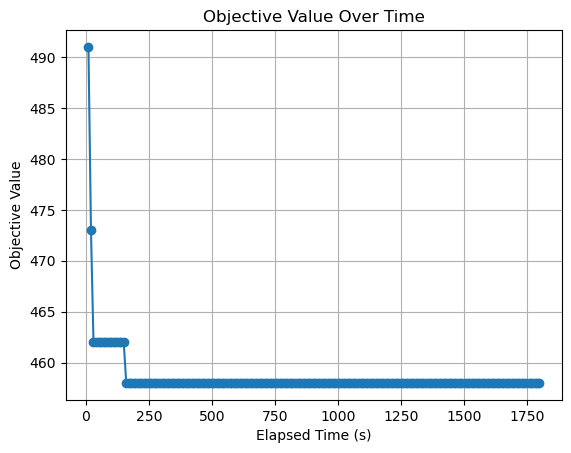

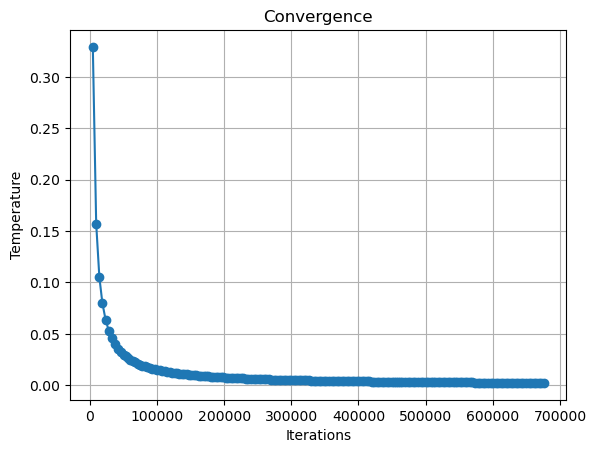

In [28]:
encoding_tuple= main_greedy_initial_SA(1800)


In [29]:
encoding_tuple
summary(encoding_tuple[0])
objective_value(encoding_tuple[0])

Feasible: True
Objective Value: 458.0
Latest Arrival Time: 594.0
No. of Locations Each FRC visits: between 3 and 7



458.0